## Producing labels for segmenting images of strong gravitational lenses

Notebook originally developed by Gillian Cartwright [Original notebook](https://github.com/gilliancartwright/Image-Segmentation/blob/main/Labeling.ipynb)

In [1]:
# sys.argv[1] = <input simulation file name>, sys.argv[2] = <output labeled file>
script = False
cluster = False

In [2]:
import sys
import math
import statistics
import matplotlib.pyplot as plt
import numpy as np
from numpy.ma import masked_array
from scipy import ndimage as ndi
import scipy as sp
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as plticker
from astropy.io import fits
from astropy.visualization import make_lupton_rgb
from astropy.table import Table

if script:
    from tqdm import tqdm
else:
    from tqdm.notebook import tqdm

plt.style.use('dark_background')

In [3]:
# set file path
if cluster:
    filepath = ''
    filename = sys.argv[1]
else:
    filepath = '/Users/jimenagonzalez/research/DSPL/Hybrid_SL_Modeling/Segmentation/simulations/data/'
    filename = 'simulation_file_500.fits'

filename = filepath + filename
NUM_PIX = 45  # pixels per axis
DELTA_PIX = 0.2637  #  pixel size in arcsec

In [4]:
def normalize(flat):
    """
    Normalize a 1D numpy array between 0-1
    Args:
        * flat {numpy 1D array}: array to be normalized
    Returns: normalized 1D numpy array
    """
    MIN = np.min(flat)
    MAX = np.max(flat)
    for i in range(len(flat)):
        flat[i] = (flat[i]-MIN)/(MAX-MIN)

    return flat



In [5]:
def rgb_graphs(sim_i, sim_r, sim_g, cutout_i, cutout_r, cutout_g):
    """
    Plot three rgb plots per object: source simulation, lens cutout, and combined
    Args:
        * sim_i: i-band source light simulation
        * sim_r: r-band source light simulation
        * sim_6: g-band source light simulation
        * cutout_i: i-band lens cutout
        * cutout_r: r-band lens cutout
        * cutout_g: g-band lens cutout
    Returns: RGB image of complete simulation
    """
    sim_rgb = make_lupton_rgb(sim_i, sim_r, sim_g, Q=11., stretch=40.)
    cutout_rgb = make_lupton_rgb(cutout_i, cutout_r, cutout_g, Q=11., stretch=40.)
    rgb = make_lupton_rgb(sim_i+cutout_i, sim_r+cutout_r, sim_g+cutout_g, Q=11., stretch=40.)

    # if in notebook, show plots
    if script == False:
        loc = plticker.MultipleLocator(base=3.75)
        fig, ax = plt.subplots(figsize=(15, 4), ncols=3)
        
        ax[0].set_title('Source(s)')
        ax[0].axis('off')
        ax[0].imshow(sim_rgb, aspect='equal')

        ax[1].set_title('Lens')
        ax[1].axis('off')
        ax[1].imshow(cutout_rgb, aspect='equal')

        ax[2].set_title('Complete Simulation')
        ax[2].axis('off')
        ax[2].imshow(rgb, aspect='equal')

        plt.show()
        plt.close()

    return rgb

In [6]:
def create_source_mask(image):
    """
    Create mask that marks where source light is
    Args:
        * image {(3, pix, pix) numpy array}: 3-channel (rgb) simulated source
        * MIN {float}: value between 0-1 that sets cut-off for source light
    Returns {2D numpy array}: source mask
    """
    # turn image into normalized list
    super_image = np.add(image[0], np.add(image[1], image[2]))
    pix_list = super_image.flatten()
    normalized = normalize(pix_list)

    # re-normalize
    MIN=0.2
    for i in range(len(pix_list)):
        if normalized[i] > MIN:  # pixel has light value
            pix_list[i] = pix_list[i] # normalized value between 0-1
        else:
            pix_list[i] = 0

    # turn masked list back into 2d shape
    masked = np.reshape(pix_list, image[0].shape)

    return masked


def processing_mask(masked):
    noise = masked[2]
    
    # Getting rid of 1 pixel Noise blobs
    binary = noise.astype(bool)
    structure = ndi.generate_binary_structure(2, 2)  # 8-connected, including diagonals, other: (2,1)
    new_labels, n_blobs = ndi.label(binary, structure=structure)
    sizes_all = np.bincount(new_labels.ravel())
    noise[sizes_all[new_labels] == 1] = 0
    
    # When there are 5 or more Noise blobs, remove all the blobs with size 3 pixels or smaller
    binary = noise.astype(bool)
    new_labels, _ = ndi.label(binary, structure=structure)
    sizes_all = np.bincount(new_labels.ravel())
    n_blobs = np.count_nonzero(sizes_all[1:])
    if n_blobs >= 5:
        noise[np.isin(sizes_all[new_labels], [2, 3])] = 0
    
    masked[2] = noise
    return(masked)

In [7]:
def lens_and_background_mask(image, row, lens_z, noise_z):    
    """
    Create a mask that marks pixels as 'lens' or 'noise' classes
    Args:
        * image {(3, pix, pix) array}: rgb lens cutout
        * row {int}: row of data table to get i-band flux radius
        * cutoff {float}: number of sigma above average that pixels are considered 
                          'lens' or 'noise'
                          * 'noise' get additional 0.1 sigma
                             to avoid marking 'lens' pixels as 'noise'
    Returns {(pix, pix) array}: array of mask for lens and noise
    """
    message = 'OK'
    # make a list of coordinates (not arcsec)
    pix = len(image[0, :, 0])
    start = -(np.floor(0.5*pix))
    end = np.ceil(0.5*pix)
    X2d, Y2d = np.meshgrid(np.arange(start, end), np.arange(start, end))
    coords = np.column_stack((Y2d.ravel(), X2d.ravel())).tolist()

    # make list of distances to center from coordinate list
    dist_from_center = []
    for i in range(len(coords)):
        distance = np.sqrt(coords[i][0] ** 2 + coords[i][1] ** 2)
        dist_from_center.append(distance)

    # turn image into normalized list
    super_image = np.add(image[0], np.add(image[1], image[2]))
    pix_list = super_image.flatten()
    normalized = pix_list # normalized

    # set light value cutoff
    mean = np.mean(normalized)
    stdev = np.std(normalized)
    lens_cutoff = mean + lens_z * stdev
    noise_cutoff_high = mean + (lens_z+0.1) * stdev
    
    noise_cutoff_low = mean + noise_z*stdev
    if noise_cutoff_low < 20:
        noise_cutoff_low=20

    # set max radius to look for lens light:
    #     if distance to farthest source image is smaller than 1.2*(avg. flux radius),
    #     then use 1.2*(avg. flux radius) as lens light radius
    f_radius = np.mean([data.iloc[row, 7:10]])  # average flux radius across g, r, i bands
    radius_p = data['POSITION1'].iloc[row]  # distance from center to farthest source image

    # experimentation has shown that just using average flux rad. is too small, so use 1.2*flux rad.
    min_multiply = 1.2
    min_rad = min_multiply * f_radius
    if radius_p < min_rad:
        radius = min_rad

    else:
        radius = radius_p

    # iterate through pixels and set corresponding values
    lens_coords = []
    lens_list = np.zeros(len(pix_list))
    noise_coords = []
    noise_list = np.zeros(len(pix_list))
    loop_count = 0

    # while less than 20 pixels are marked as 'lens',
    # continue to lower the cutoff value until enough pixels are 'lens'
    while len(lens_coords) <= 20:
        # catch infinite loop
        if loop_count > 15:
            lens_cutoff = 0.001  # any pixel with light value in radius will be marked lens
            radius = radius + 5  # widen radius in case too small
            message = 'ERROR'
            print("ERROR!")  # flag as 'ERROR'

        # iterate through pixels to look for 'lens' within circle of 'radius'
        for i in range(len(pix_list)):
            if normalized[i] > lens_cutoff and dist_from_center[i] < radius:
                lens_coords.append(i)  # mark coordinate as 'lens'
                lens_list[i] = pix_list[i]  # update 'lens' with pixel val

        # lower light value thresholds
        lens_cutoff -= 0.02
        noise_cutoff_high -= 0.02
        
        # fix thresholds if too small
        if lens_cutoff < 0.005:
            lens_cutoff = 0.005
            noise_cutoff_high = 0.02

        if len(lens_coords) <= 20:
            if script == False:
                print('REPEATING LOOP')  # for testing
            loop_count += 1  # for catching infinite loop

    # look through the pixels not marked as 'lens'
    for i in range(len(pix_list)):
        if dist_from_center[i]>(radius+1) and dist_from_center[i]<(radius+5):
            if normalized[i] > noise_cutoff_high:  # mark as 'noise'
                noise_coords.append(i)
                noise_list[i] = pix_list[i]
        elif dist_from_center[i]>=radius+5:
            if normalized[i] > noise_cutoff_low:  # mark as 'noise'
                noise_coords.append(i)
                noise_list[i] = pix_list[i]
    # reshape into original size and normalize
    lens = np.reshape(normalize(lens_list), (pix, pix))
    noise = np.reshape(normalize(noise_list), (pix, pix))

    return message, lens, noise

In [8]:
def mask_image(coadd_id, lens_z, noise_z, pix):
    """
    Mask a single image so each pixel is categorized as 'source', 'lens', or 'noise'
    Args:
        * coadd_id: 'Y6_COADD_OBJECT_ID' of candidate
        * noise_cutoff: pixels outside 2(flux rad) that are greater than
                        noise_cutoff are marked as noise
        * lens_cutoff: pixels within 2(flux rad) > that are greater than 
                       lens_cutoff are marked as lens light
    Returns: 
        * rgb: rgb graphs of original source simulation, lens, and complete image
        * masked_source: 2d np array marking pixels where source light is
        * masked_lens: 2d np array marking pixels where lens and nosie is
        * masked: 2d np array with complete image labeled for source, lens, and noise
    """
    # index by coadd_id
    row = data[data['Y6_COADD_OBJECT_ID'] == coadd_id].index[0]

    # original simulation
    source_g, source_r, source_i = source_sim[row][0], source_sim[row][1], source_sim[row][2]
    lens_g, lens_r, lens_i = lens_sim[row][0], lens_sim[row][1], lens_sim[row][2]
    rgb = rgb_graphs(source_i, source_r, source_g, lens_i, lens_r, lens_g)

    # apply masks to source and lens
    masked_source = create_source_mask(source_sim[row])
    message, masked_lens, masked_noise = lens_and_background_mask(lens_sim[row], row, lens_z, noise_z)
    
    # ensure each pixel belongs to ONLY ONE class
    s_list = masked_source.flatten()  # 0
    l_list = masked_lens.flatten()  # 1
    n_list = masked_noise.flatten()  # 2
    b_list = np.empty((pix, pix)).flatten()  # 3
    
    for i in range(len(s_list)):
        if n_list[i] > 0:
            if s_list[i]>n_list[i]:
                s_list[i], l_list[i], n_list[i], b_list[i] = 1, 0, 0, 0
            else:
                s_list[i], l_list[i], n_list[i], b_list[i] = 0, 0, 1, 0

        elif s_list[i] > 0:
            if l_list[i] >= s_list[i]:
                s_list[i], l_list[i], n_list[i], b_list[i] = 0, 1, 0, 0

            else:
                s_list[i], l_list[i], n_list[i], b_list[i] = 1, 0, 0, 0

        elif l_list[i] > 0:
            s_list[i], l_list[i], n_list[i], b_list[i] = 0, 1, 0, 0

        else:
            s_list[i], l_list[i], n_list[i], b_list[i] = 0, 0, 0, 1

    # combine and reshape
    masked = np.empty((4, pix, pix))
    masked[0] = np.reshape(s_list, masked[0].shape)  # 0
    masked[1] = np.reshape(l_list, masked[1].shape)  # 1
    masked[2] = np.reshape(n_list, masked[2].shape)  # 2
    masked[3] = np.reshape(b_list, masked[3].shape)  # 3

    # Processing labels (removing very small Noise blobs)
    masked = processing_mask(masked)
    
    # plot if in notebook
    if script == False:
        fig, ax = plt.subplots(1, 3, figsize=(15, 4))

        img1 = ax[0].imshow(masked_source, cmap='magma')
        ax[0].set_title('Source(s) Mask')
        ax[0].axis('off')

        smooth_lens = masked_array(masked_lens, masked_lens==0)  # when lens is 1 show lens
        smooth_noise = masked_array(masked_noise, masked_noise==0)  # when noise is 1 show noise
        
        ax[1].imshow(smooth_lens, interpolation='nearest', cmap='spring')
        ax[1].imshow(smooth_noise, interpolation='nearest', cmap='summer')
        ax[1].set_title('Lens Mask')
        ax[1].axis('off')
        
        lens = masked_array(masked[1], masked[1]!=1)  # when lens is 1 show lens
        noise = masked_array(masked[2], masked[2]!=1)  # when noise is 1 show noise

        ax[2].imshow(masked[0], interpolation='nearest', cmap='magma')
        ax[2].imshow(lens, interpolation='nearest', cmap='spring')
        ax[2].imshow(noise, interpolation='nearest', cmap='summer')
        ax[2].set_title('All Masks')
        ax[2].axis('off')

        plt.show()
    
    return message, rgb, masked

In [9]:
def masking_all(pix, num):
    """
    Mask [num] simulations & show progress bar
    Args:
    * pix {int}: pixels per axis
    * num {int}: number of images to mask
    Returns:
    """
    masks_complete = np.zeros((1, 4, pix, pix))
    indices_remove = []

    with tqdm(total=num) as pbar:
        for (index, row) in data[:num].iterrows():
            message, rgb, masked = mask_image(row['Y6_COADD_OBJECT_ID'], 1.7, 0.5, pix)
            if not script:
                print(row['Y6_COADD_OBJECT_ID'])
            if(message == 'ERROR'):
                indices_remove.append(index)
            
            masks_complete = np.append(masks_complete, [masked], axis=0)
            pbar.update(1)

    masks_complete = np.delete(masks_complete, 0, axis=0)
    
    return indices_remove, masks_complete


In [10]:
def write_fit_file(name, images, data):
    """
    writes fits file with simulation data, simulation images, and mask images
    """
    my_types = {'Y6_COADD_OBJECT_ID': int, 'TILENAME': str, 'HPIX_16384': int, 'HPIX_4096': int,
       'DNF_ZMEAN_SOF': float, 'RA': float, 'DEC': float, 'FLUX_RADIUS_G': float, 'FLUX_RADIUS_R': float,
       'FLUX_RADIUS_I': float, 'FLUX_RADIUS_Z': float, 'KRON_RADIUS': float, 'GAP_FLUX_G': float,
       'MOF_BDF_FLUX_G': float, 'MOF_PSF_FLUX_G': float, 'SOF_BDF_FLUX_G': float, 'SOF_PSF_FLUX_G': float,
       'MAG_AUTO_G': float, 'MAG_APER_4_G': float, 'MAG_APER_8_G': float, 'SOF_BDF_G_1': float,
       'Y3_COADD_OBJECT_ID': int, 'REFMAG': float, 'REFMAG_ERR': float, 'LUM': float, 'ZREDMAGIC': float,
       'ZREDMAGIC_E': float, 'CHISQ': float, 'Z_LENS': float, 'MAG_G': float, 'MAG_R': float, 'MAG_I': float, 'MAG_Z': float,
       'MAG_ERR_G': float, 'MAG_ERR_R': float, 'MAG_ERR_I': float, 'MAG_ERR_Z': float, 'ZG': float, 'ZR': float, 'ZI': float,
       'ZZ': float, 'SOF_BDF_G_2': float, 'IMAFLAGS_ISO_G': int, 'IMAFLAGS_ISO_R': int,
       'IMAFLAGS_ISO_I': int, 'IMAFLAGS_ISO_Z': int, 'EXT_COADD': int, 'FWHM_WMEAN_G': float,
       'FWHM_WMEAN_R': float, 'FWHM_WMEAN_I': float, 'FWHM_WMEAN_Z': float, 'SKYBRITE_WMEAN_G': float,
       'SKYBRITE_WMEAN_R': float, 'SKYBRITE_WMEAN_I': float, 'SKYBRITE_WMEAN_Z': float, 'Z1': float, 'LENSED_MAG': float,
       'mag_1': float, 'ISOLATION': float, 'EINSTEIN_RADIUS': float, 'MAGNIFICATION': float, 'POSITION1': float}
    data = data.astype(my_types)

    primary = fits.PrimaryHDU()
    image1 = fits.ImageHDU(images[0], name="IMAGE")
    image2 = fits.ImageHDU(images[1], name="IMAGE")
    image3 = fits.ImageHDU(images[2], name="IMAGE")
    image4 = fits.ImageHDU(images[3], name="IMAGE")
    table_data = Table.from_pandas(data)
    table = fits.BinTableHDU(data = table_data)
    hdu_list = fits.HDUList([primary, image1, image2, image3, image4, table])
    hdu_list.writeto(name + '.fits', overwrite=True)
    hdu_list.close()


20 20 20 20


  0%|          | 0/20 [00:00<?, ?it/s]

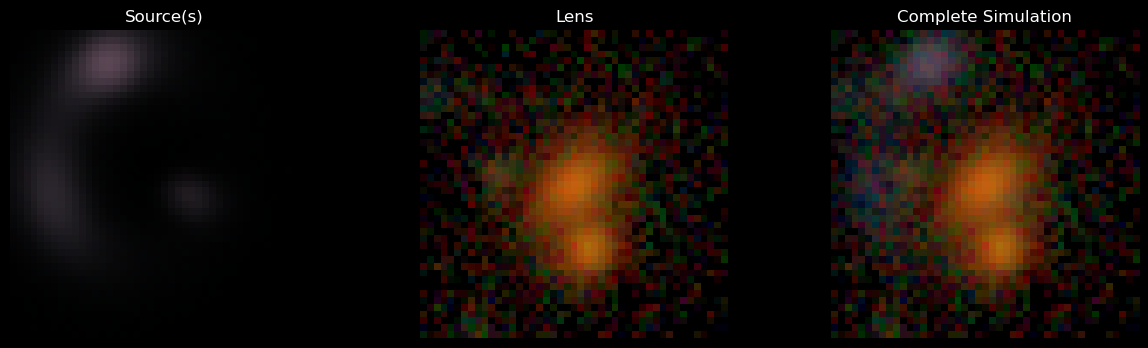

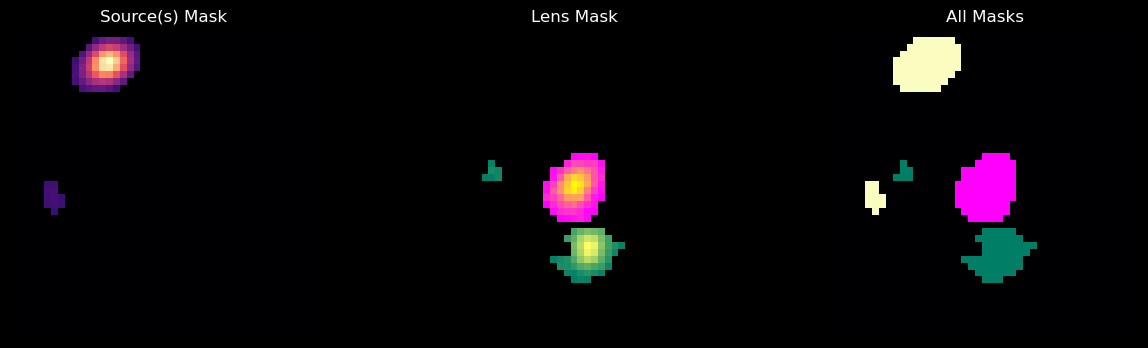

1109488450


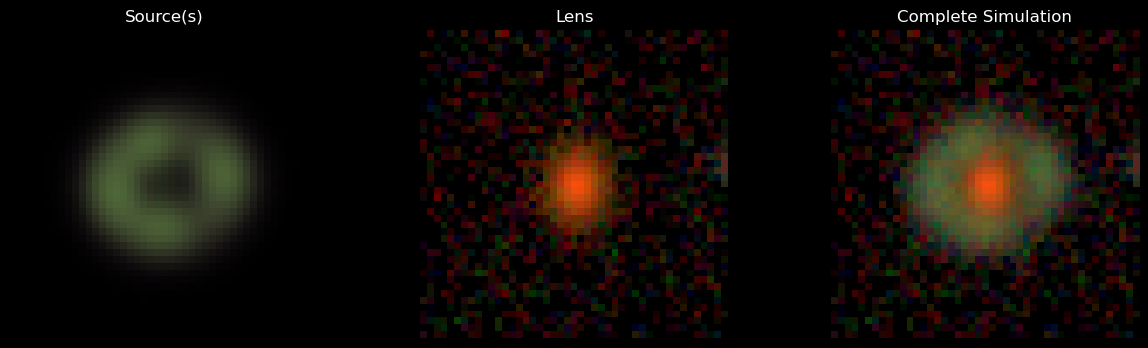

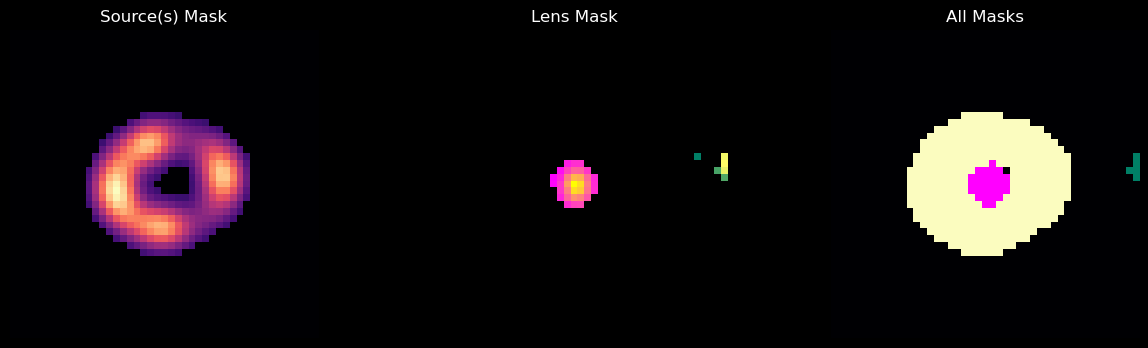

1254693043


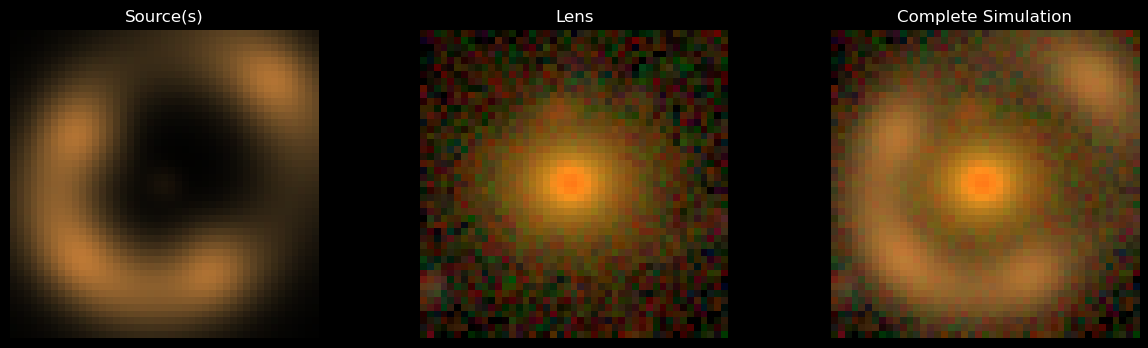

/Users/jimenagonzalez/Software/miniconda3/lib/python3.7/site-packages/ipykernel_launcher.py:11: RuntimeWarning: invalid value encountered in double_scalars
  # This is added back by InteractiveShellApp.init_path()
/Users/jimenagonzalez/Software/miniconda3/lib/python3.7/site-packages/matplotlib/image.py:443: UserWarning: Warning: converting a masked element to nan.
  dv = np.float64(self.norm.vmax) - np.float64(self.norm.vmin)
/Users/jimenagonzalez/Software/miniconda3/lib/python3.7/site-packages/matplotlib/image.py:444: UserWarning: Warning: converting a masked element to nan.
  vmid = np.float64(self.norm.vmin) + dv / 2


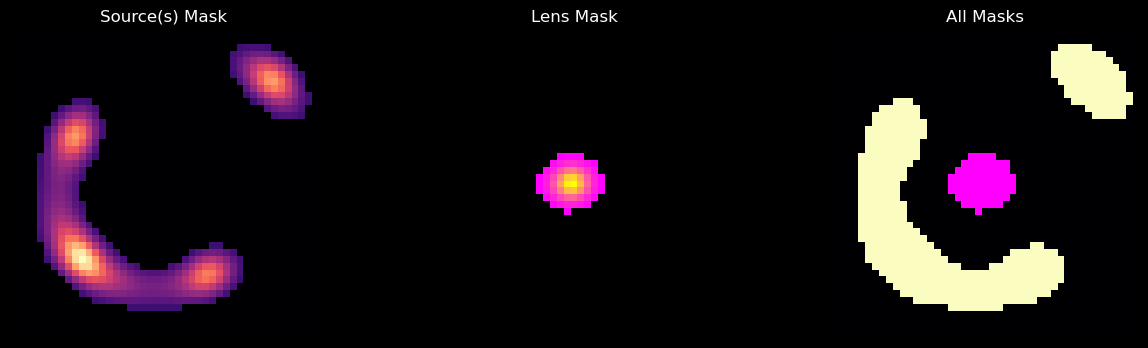

1144923580


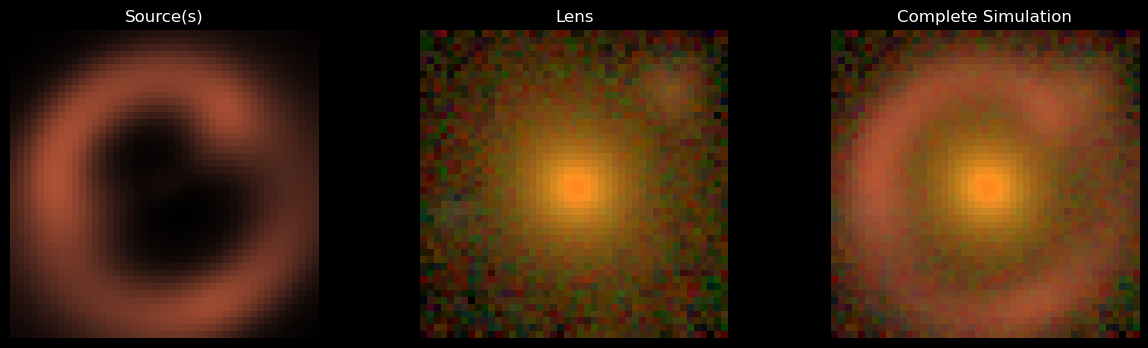

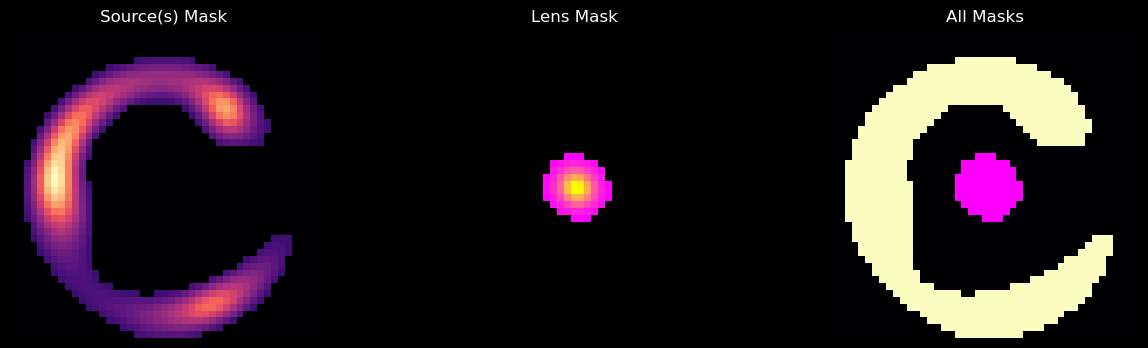

1030691273


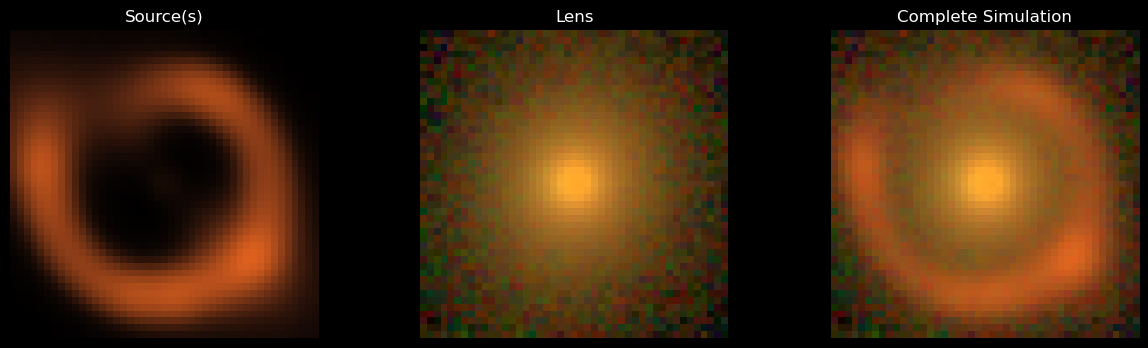

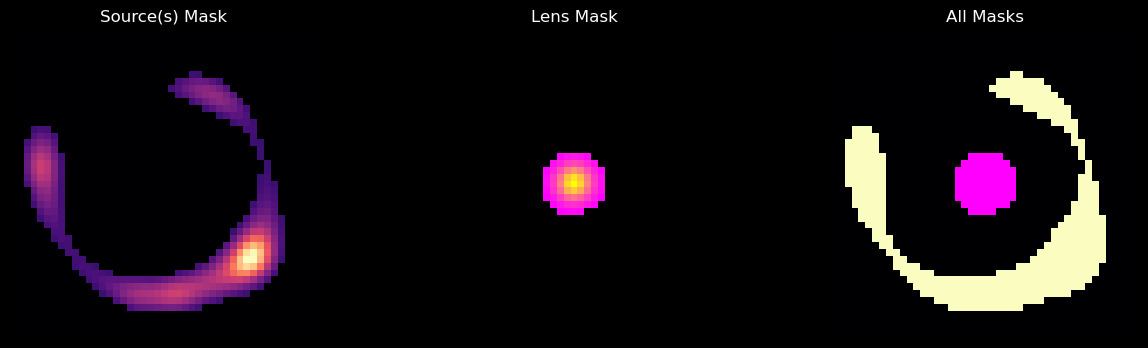

1313258079


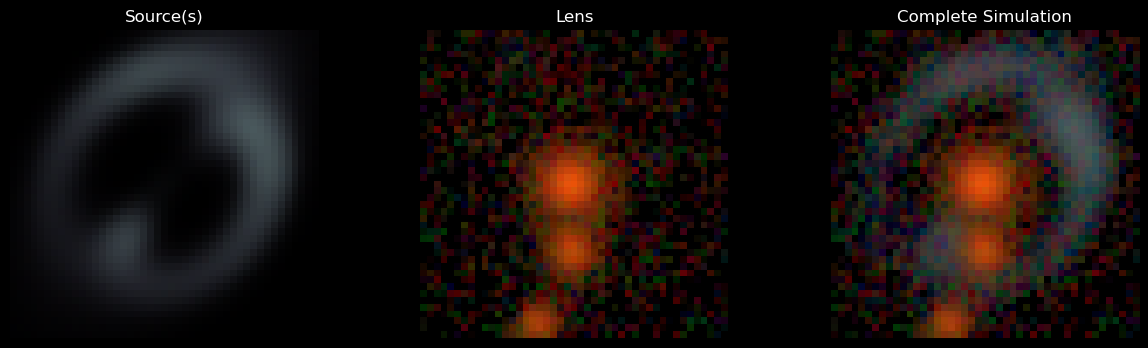

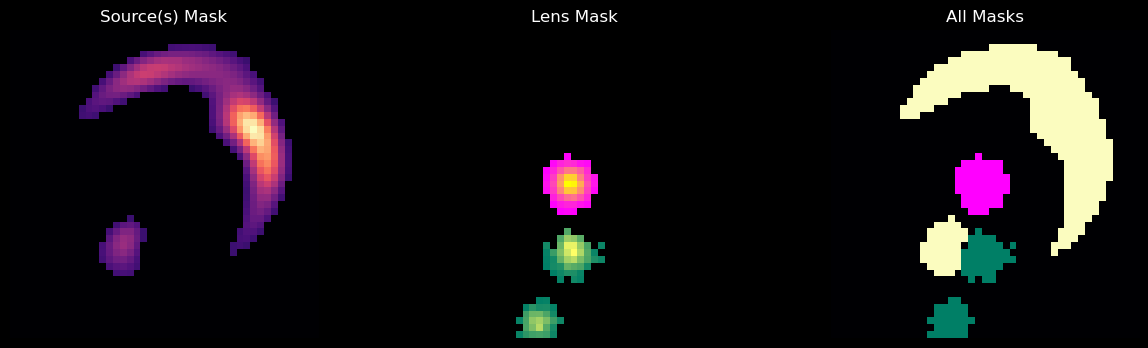

1238585428


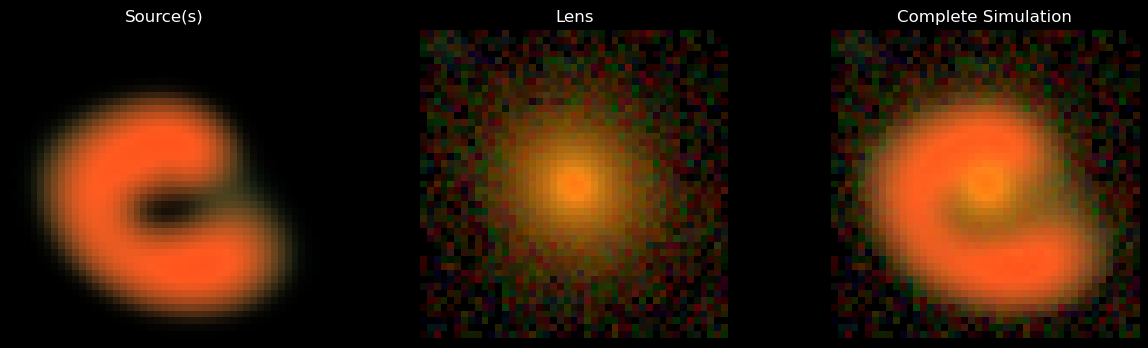

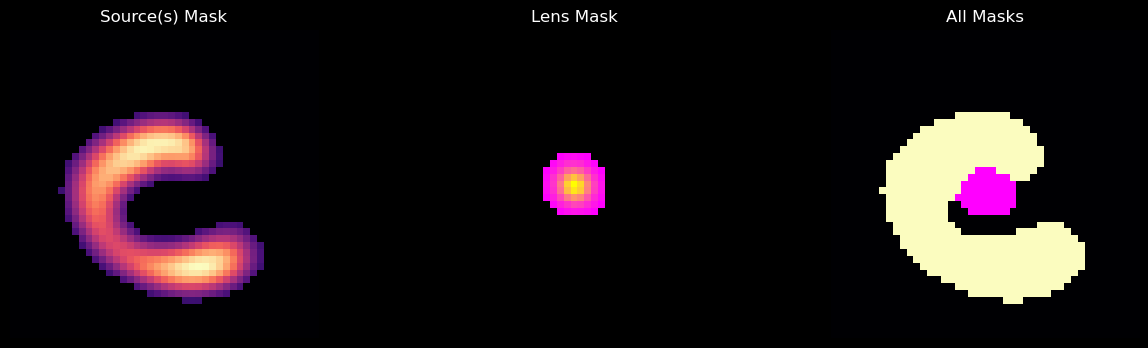

1033340890


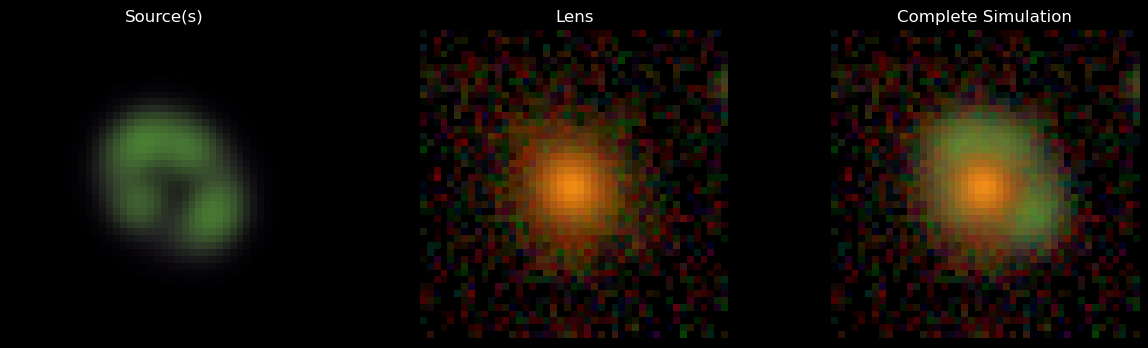

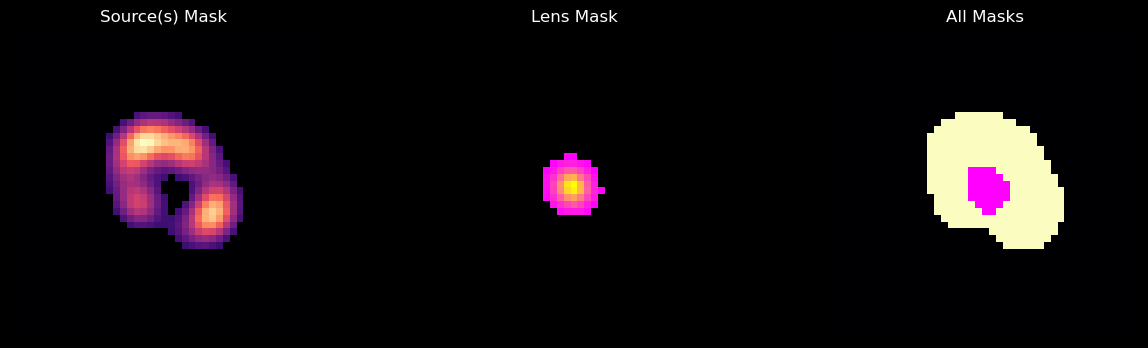

1233802336


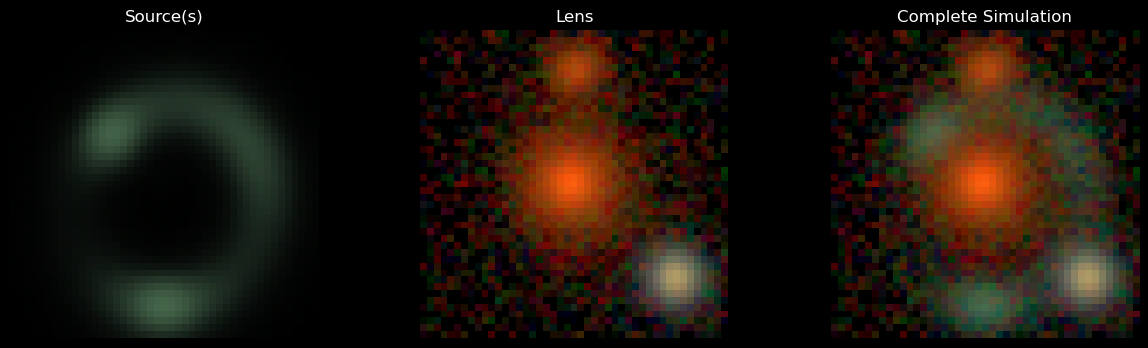

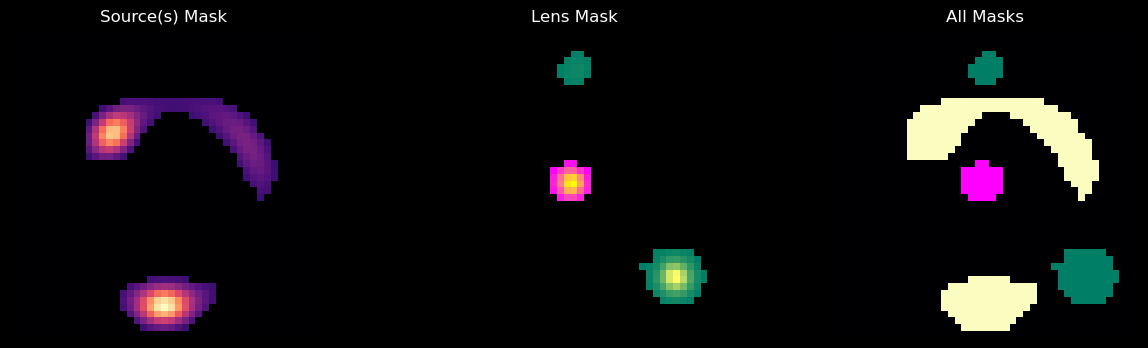

1198169513


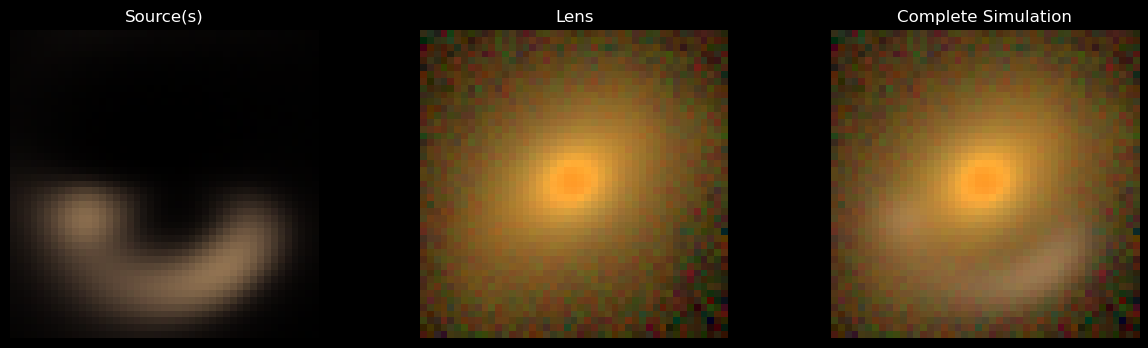

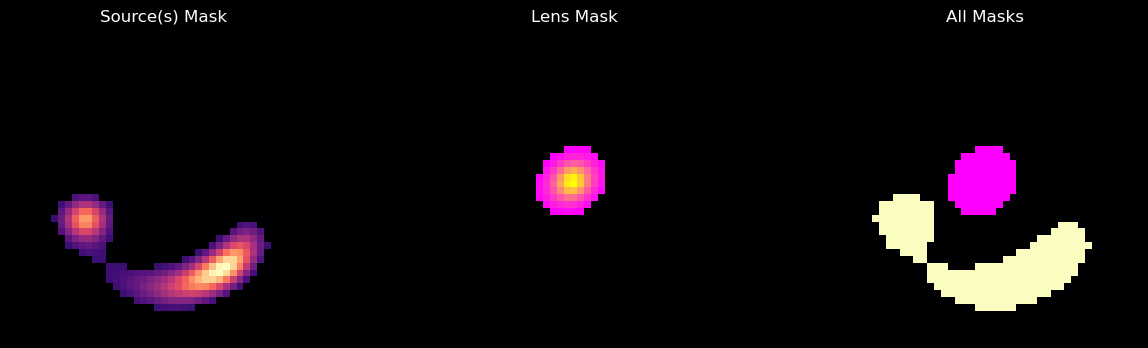

1055052041


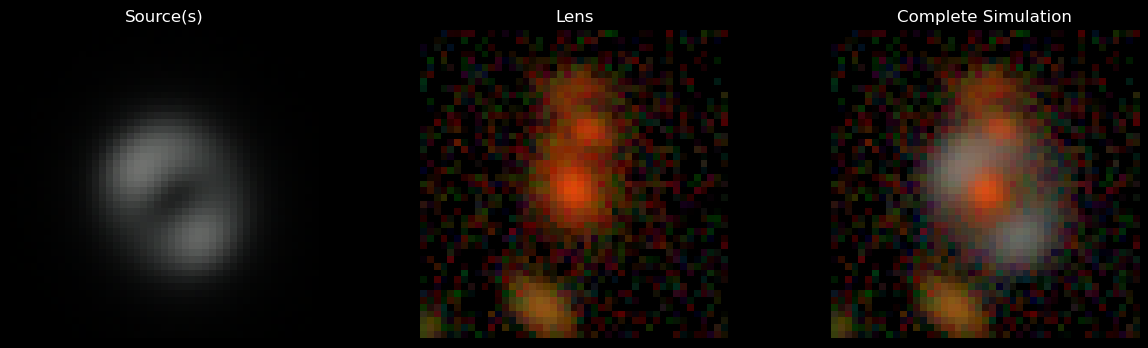

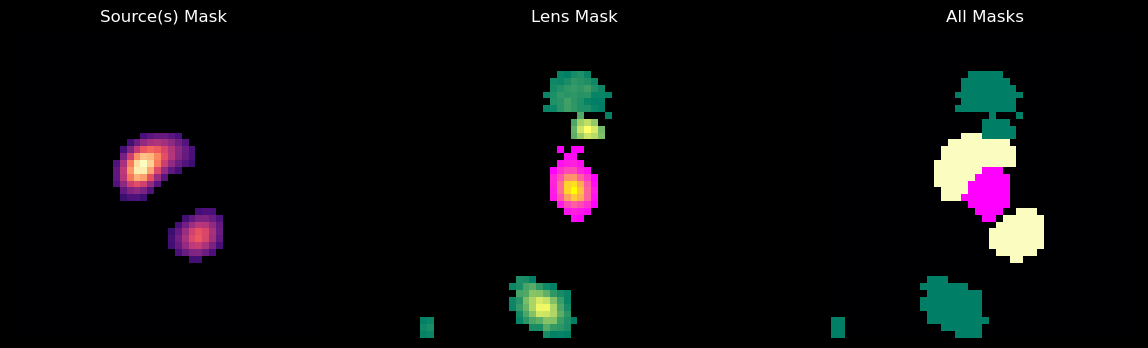

916025740


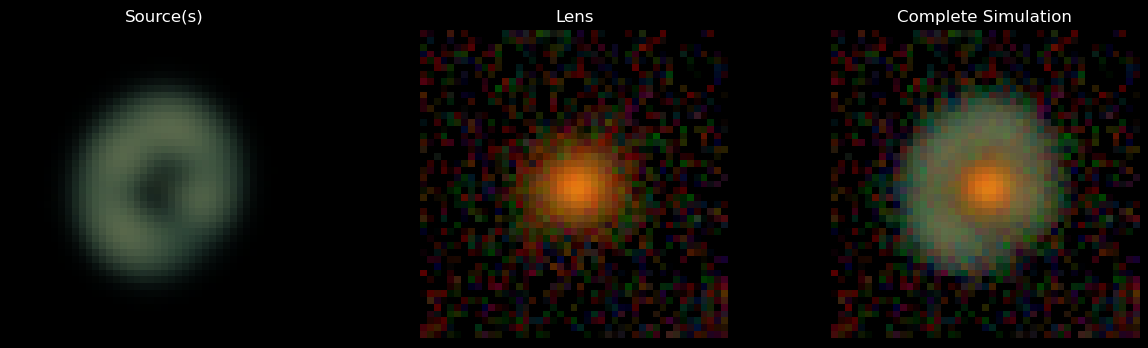

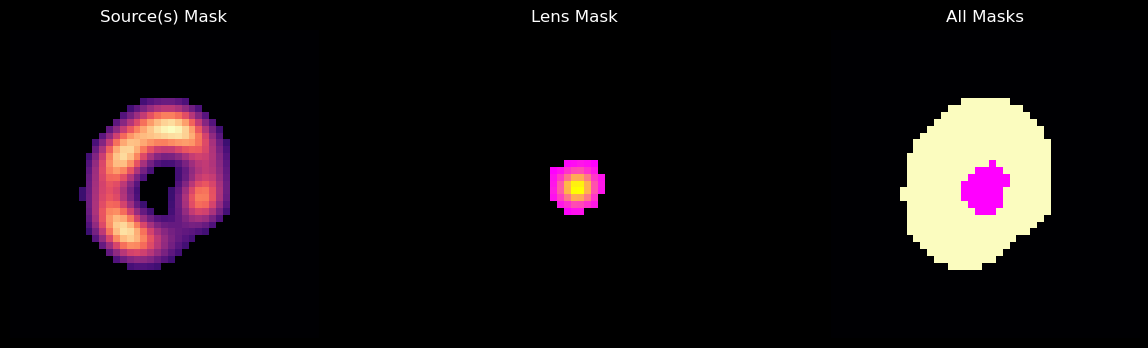

1068123567


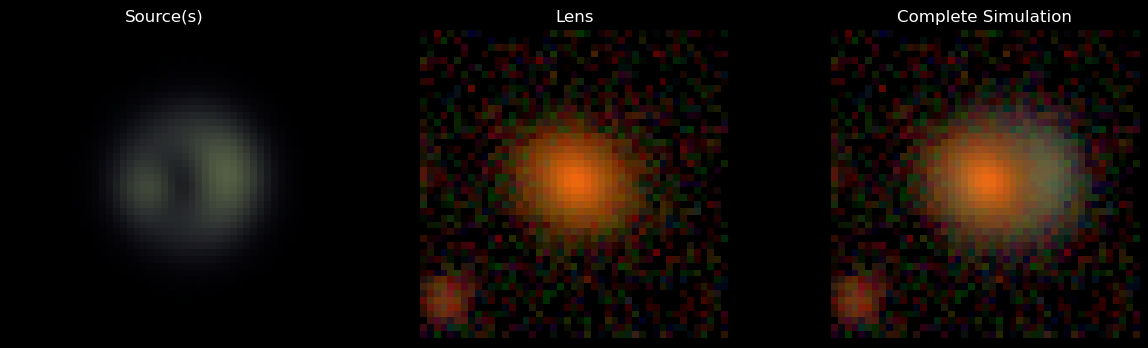

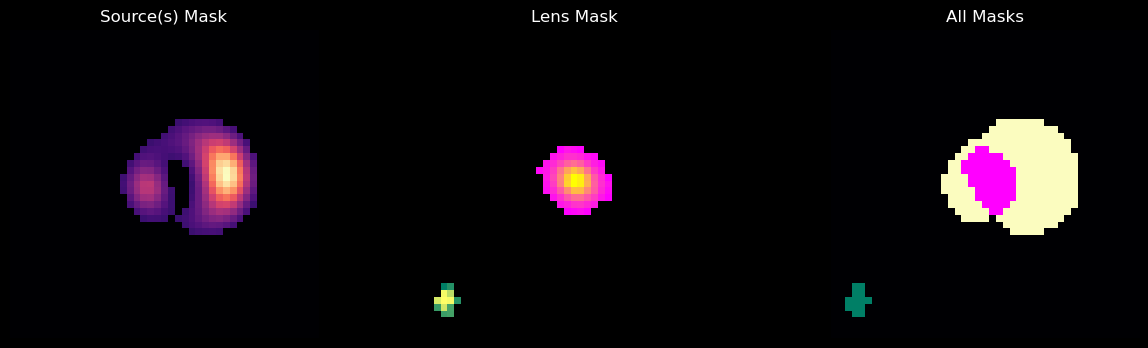

1042537610


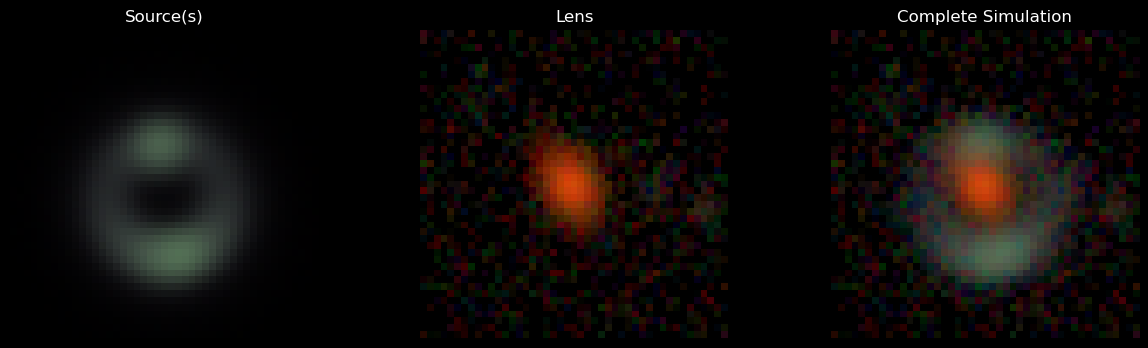

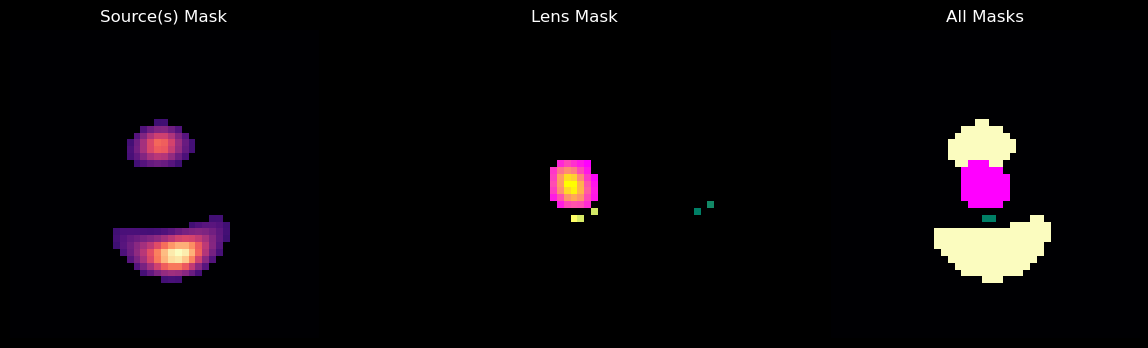

1207705708


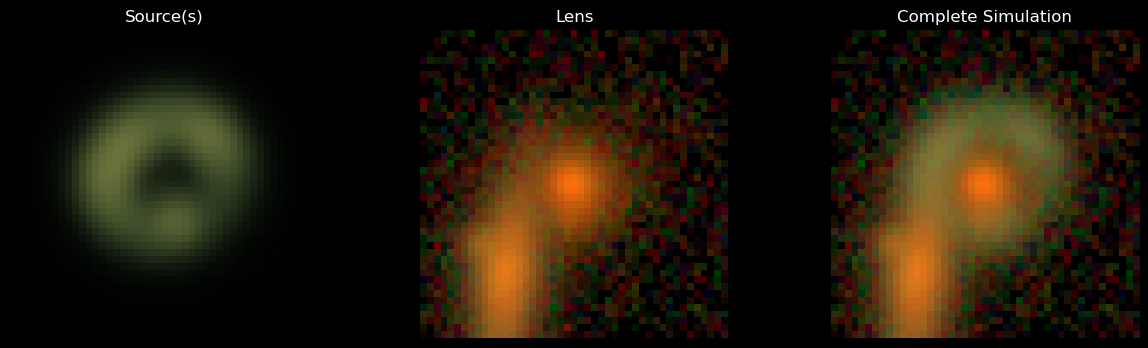

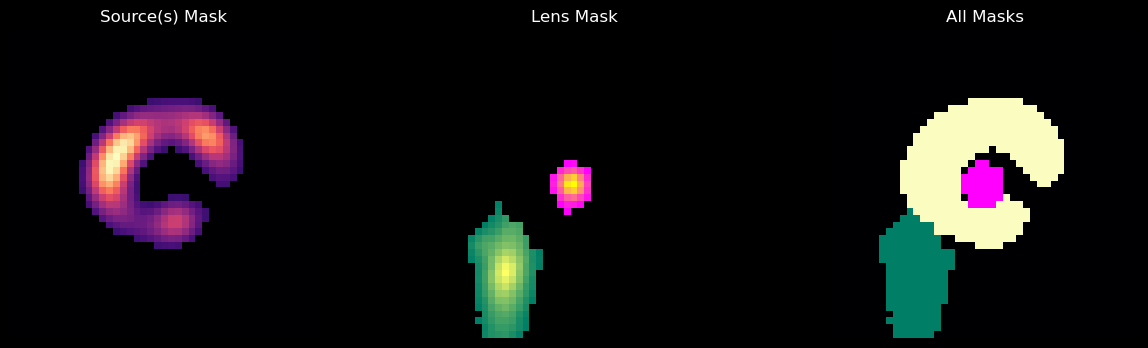

1092765874


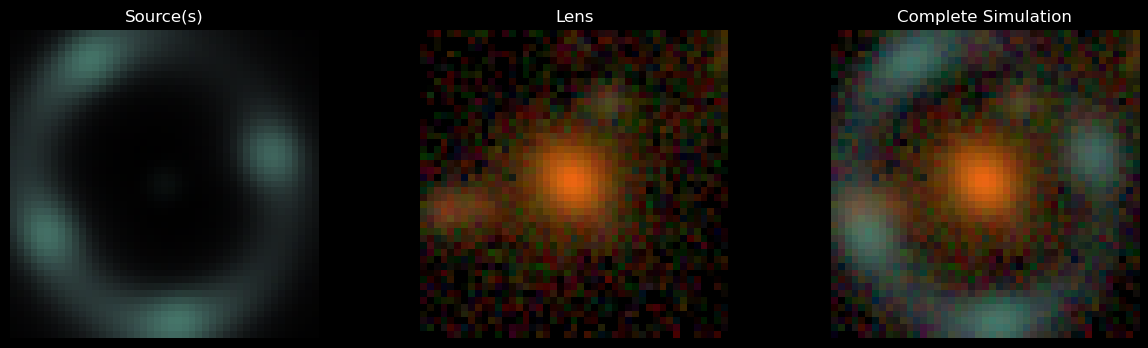

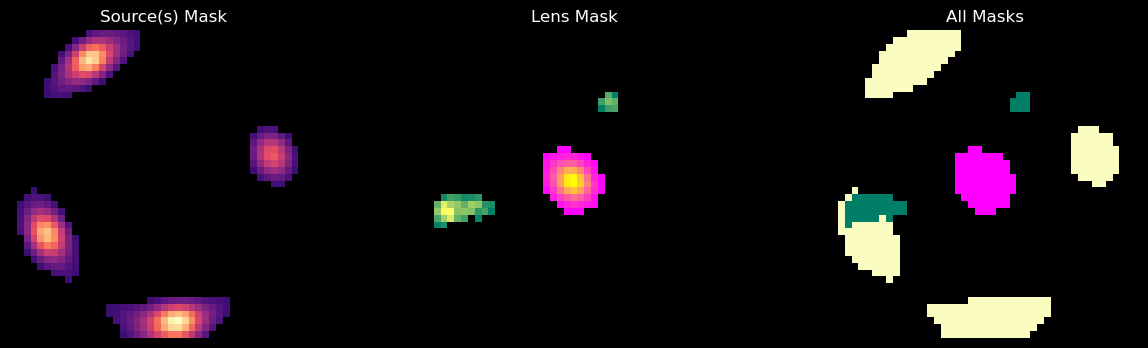

1141142956


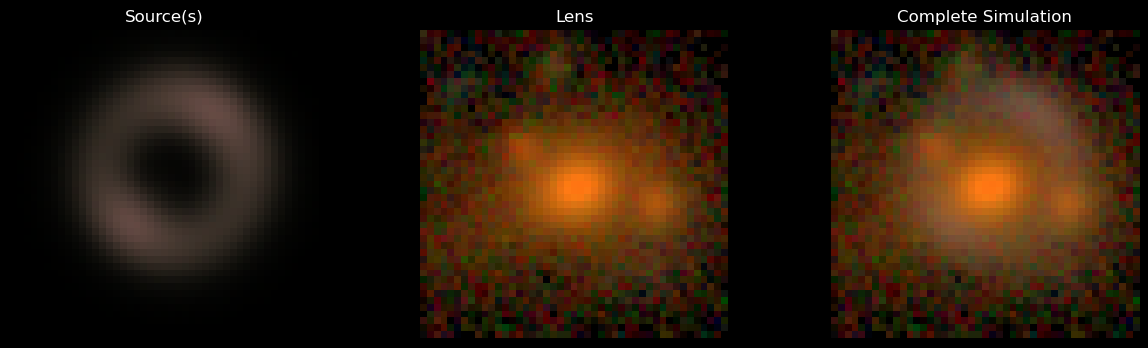

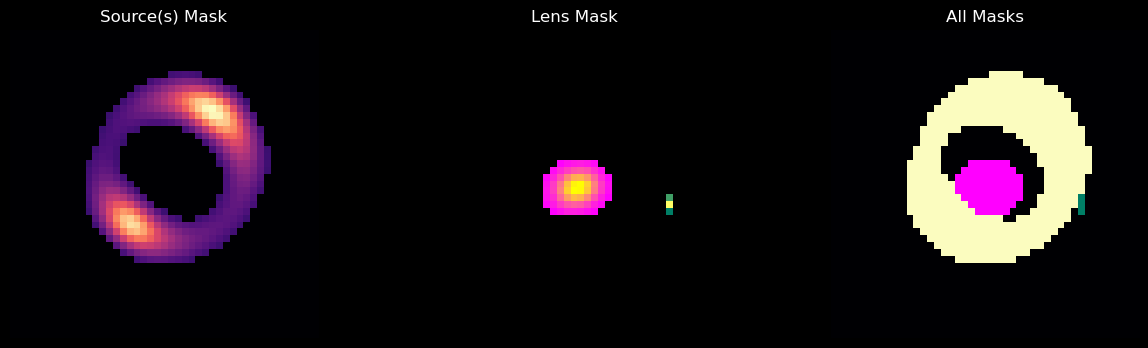

1270531417


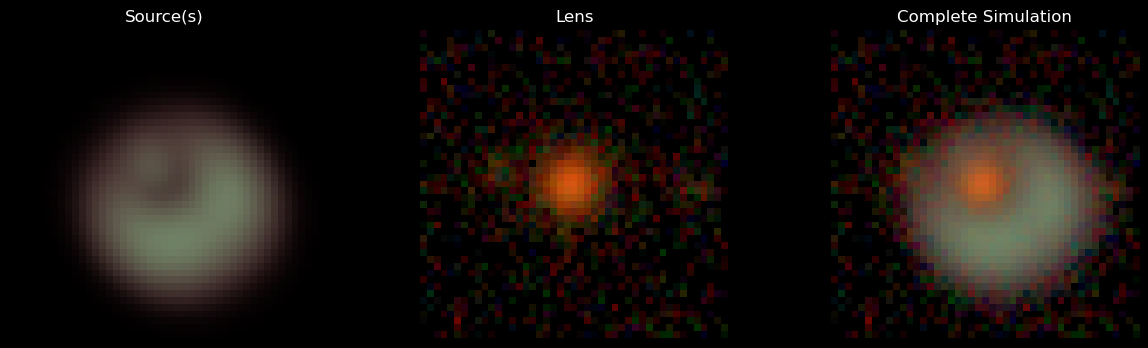

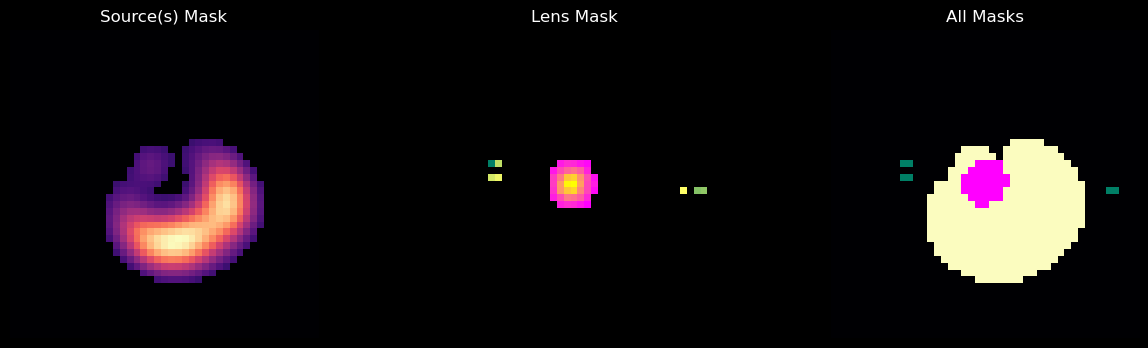

1234533491


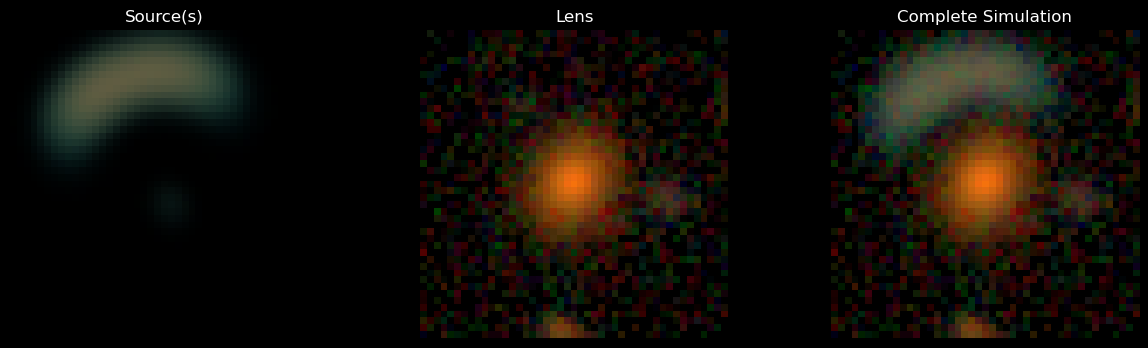

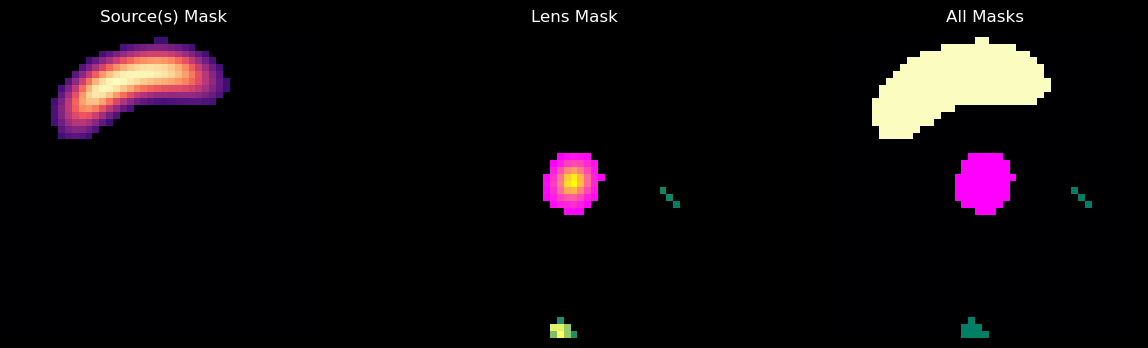

1093997992


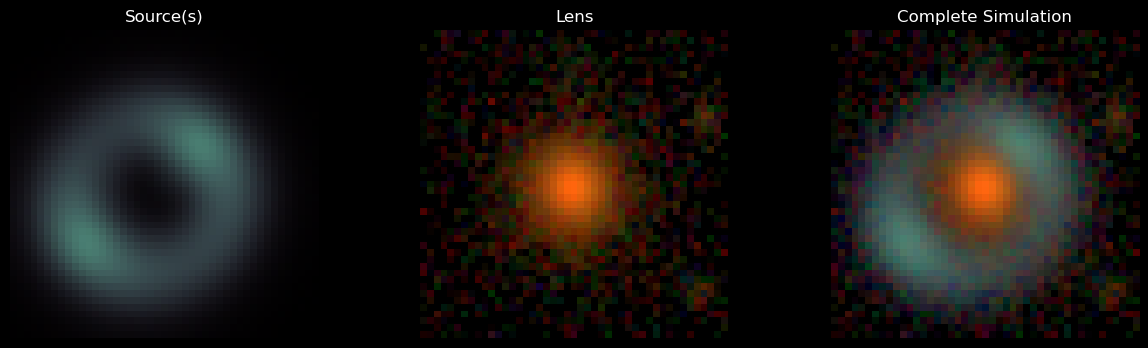

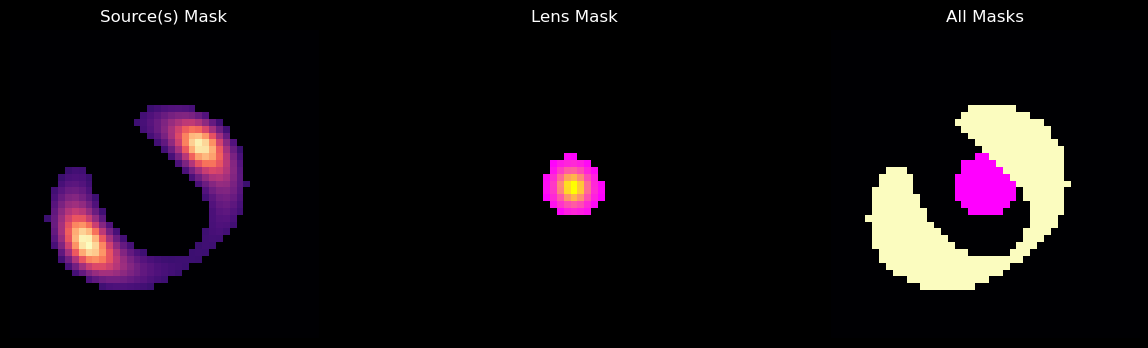

966798677
20 20 20


In [11]:
if script:
    output_filename = 'exp_' + str(sys.argv[2])
else:
    output_filename = 'labeled_simulations'

num_label = 20 # For notebook, if cluster is complete length of the simulation file

# get data from fits
hdu_list = fits.open(filename)
if(cluster): num_label = len(hdu_list[1].data)
complete_sim = hdu_list[1].data[0:num_label]
source_sim = hdu_list[2].data[0:num_label]
lens_sim =hdu_list[3].data[0:num_label]
data = pd.DataFrame(hdu_list[4].data).iloc[0:num_label]
hdu_list.close()
print(num_label, len(complete_sim), len(source_sim), len(data))

indices_remove, masks_complete = masking_all(NUM_PIX, num_label)

#Removing datapoints with labels that fail
rm = set(indices_remove)
keep_idx = [i for i in range(len(complete_sim)) if i not in rm]
complete_sim    = [complete_sim[i] for i in keep_idx]
source_sim      = [source_sim[i] for i in keep_idx]
lens_sim        = [lens_sim[i] for i in keep_idx]
masks_complete  = [masks_complete[i] for i in keep_idx]
data = data.iloc[keep_idx].reset_index(drop=True)
print(len(complete_sim), len(source_sim), len(data))

images = [complete_sim, source_sim, lens_sim, masks_complete]
write_fit_file(output_filename, images, data)